In [12]:
pip install pandas pandas_ta numpy statsmodels arch matplotlib yfinance scipy filterpy


In [13]:

import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt
import statsmodels.api as sm
from arch import arch_model
import warnings
import pandas_ta as ta
warnings.filterwarnings('ignore')
import yfinance as yf
from scipy.stats import norm
import datetime
from filterpy.kalman import KalmanFilter

In [14]:
# Define tickers and parameters
tickers = [
  #  "EURUSD=X",
  #   "GBPUSD=X",
  #   "USDJPY=X",
  #   "USDCHF=X",
  #   "AUDUSD=X",
  #   "USDCAD=X",
  #   "NZDUSD=X",
  #   "EURGBP=X",
  #   "EURJPY=X",
  #   "GBPJPY=X",
  #   "CHFJPY=X",
  #   "EURAUD=X",
  #   "AUDJPY=X",
  #   "CADJPY=X",
  #   "AUDCAD=X",
  #   "AUDNZD=X",
  #   "GBPCHF=X",
  #   "NZDJPY=X",
  #   "EURCHF=X",
  #   "EURCAD=X",
  #   "GBPCAD=X",
  #  'GC=F'
  'BTC-USD', 'ETH-USD', 'SOL-USD', 'BNB-USD', 'ADA-USD',
    'XRP-USD', 'DOGE-USD', 'TRX-USD', 'LTC-USD', 'AVAX-USD', 'AAVE-USD', 'NEAR-USD',
    'RUNE-USD', 'APT-USD','BCH-USD',
     'FTM-USD', 'OP-USD',
    'DOT-USD', 'RDNT-USD'
]

# Define interval and lookback period
interval = '1h'
lookback = '2y'

# Fetch historical data for each ticker
dfs = {}
for ticker_symbol in tickers:
    df = yf.download(ticker_symbol, interval=interval, period=lookback)
    dfs[ticker_symbol] = df['Close']  # Use 'Close' prices

# Create a DataFrame from the dictionary
# price = pd.DataFrame(dfs).set_index(dfs[tickers[0]].index).dropna()
# dfs

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

In [15]:
# prompt: # Create a DataFrame from the dictionary

# Get the index from the first ticker's data
index = dfs[tickers[0]].index

# Create the DataFrame with the explicit index, squeezing to 1D
price = pd.DataFrame({k: v.squeeze() for k, v in dfs.items()}, index=index).dropna()

In [16]:
# Function to calculate best cointegration pairs with fixed window size
def find_best_cointegration(data, window_size=1000):
    best_results = []
    ticker_pairs = [(ticker1, ticker2) for i, ticker1 in enumerate(tickers) for ticker2 in tickers[i+1:]]

    for stock1, stock2 in ticker_pairs:
        # Ensure the window size does not exceed the data length
        if window_size > len(data):
            continue

        # Calculate cointegration
        score, p_value, _ = coint(data[stock1].iloc[-window_size:], data[stock2].iloc[-window_size:])

        best_results.append((stock1, stock2, window_size, score, p_value))

    # Convert results to DataFrame
    results_df = pd.DataFrame(best_results, columns=['Stock1', 'Stock2', 'Window Size', 'score', 'p-value'])
    return results_df


In [17]:
train_index = int(len(price) * 0.999)
test_index = (len(price)-train_index)

# Find the best cointegration pairs with fixed window size
cointegration_results = find_best_cointegration(price[:train_index],train_index)

In [18]:
# Create a filter for significant p-values using the top indices
filter = cointegration_results['p-value'] <= 0.05

# Use the filter to get the final results, ensuring correct alignment
results_cointegration = cointegration_results[filter]

display(results_cointegration)

,Stock1,Stock2,Window Size,score,p-value
93,DOGE-USD,TRX-USD,15150,-3.655431,0.020887
107,TRX-USD,AAVE-USD,15150,-4.837443,0.000324
156,APT-USD,BCH-USD,15150,-4.521330,0.001129
157,APT-USD,FTM-USD,15150,-4.451234,0.001471
158,APT-USD,OP-USD,15150,-5.959860,0.000002
159,APT-USD,DOT-USD,15150,-4.957353,0.000197
160,APT-USD,RDNT-USD,15150,-5.356304,0.000035
161,BCH-USD,FTM-USD,15150,-3.338833,0.049613


In [19]:
pair = results_cointegration[['Stock1', 'Stock2']].iloc[0]

# Prepare the data
y_train = price[pair[0]].values[:train_index]
X_train = price[pair[1]].values[:train_index]
pricetest = price[train_index:]

# Initialize the Kalman Filter for dynamic OLS
kf = KalmanFilter(dim_x=2, dim_z=1)
# State transition matrix (identity matrix)
kf.F = np.eye(2)
# Initial measurement matrix (will be updated with X_train[t])
kf.H = np.array([[1, 0]])
# Initial state (alpha, beta)
kf.x = np.array([[0], [0]])
# Initial covariance matrix
kf.P *= 1000.  # Large initial uncertainty
# Process noise covariance
kf.Q = np.array([[1e-5, 0], [0, 1e-5]])
# Measurement noise covariance
kf.R = np.array([[1]])

# Store estimates
alpha_estimates = []
beta_estimates = []

# Kalman filter loop for training data
for t in range(len(y_train)):
    # Update the measurement matrix to account for X_train[t]
    kf.H = np.array([[1, X_train[t]]])
    # Measurement (y_train[t])
    z = np.array([[y_train[t]]])
    # Predict
    kf.predict()
    # Update with the new observation
    kf.update(z)
    # Store the estimates
    alpha_estimates.append(kf.x[0][0])  # Store alpha
    beta_estimates.append(kf.x[1][0])   # Store beta

# For the test period, use the last estimated parameters
alpha_test = alpha_estimates[-1]
beta_test = beta_estimates[-1]

# Calculate residuals for training and testing
distance_train = y_train - (np.array(alpha_estimates) + np.array(beta_estimates) * X_train)
distance_test = pricetest[pair[0]].values - (alpha_test + beta_test * pricetest[pair[1]].values)

# Combine residuals into a single Series
distance_full = pd.Series(
    np.concatenate([distance_train, distance_test]),
    index=np.concatenate([price.index[:train_index], pricetest.index]),
    name='Distance'
)

# Define upper and lower bounds
upper = distance_train.mean() + 1.4 * distance_train.std()
lower = distance_train.mean() + -1.4 * distance_train.std()

# Create conditions for entries
entry_1 = ta.cross_value(distance_full, upper, above = True)
entry_2 = ta.cross_value(distance_full, lower, above = True)

close_signal_ = np.sign(distance_full)
close_signal = np.zeros(len(distance_full))
for i in range(1, len(close_signal)):
    if close_signal_[i - 1] != close_signal_[i]:
        close_signal[i] = 1  # Mark a close signal when the sign changes

trades_signal = []
# Iterate through the index to check for conditions
for i in range(len(distance_full)):
    if entry_1.iloc[i].any():
        trades_signal.append(1)  # Entry 1
    elif entry_2.iloc[i].any():
        trades_signal.append(2)  # Entry 2
    else: trades_signal.append(0)  # No entry

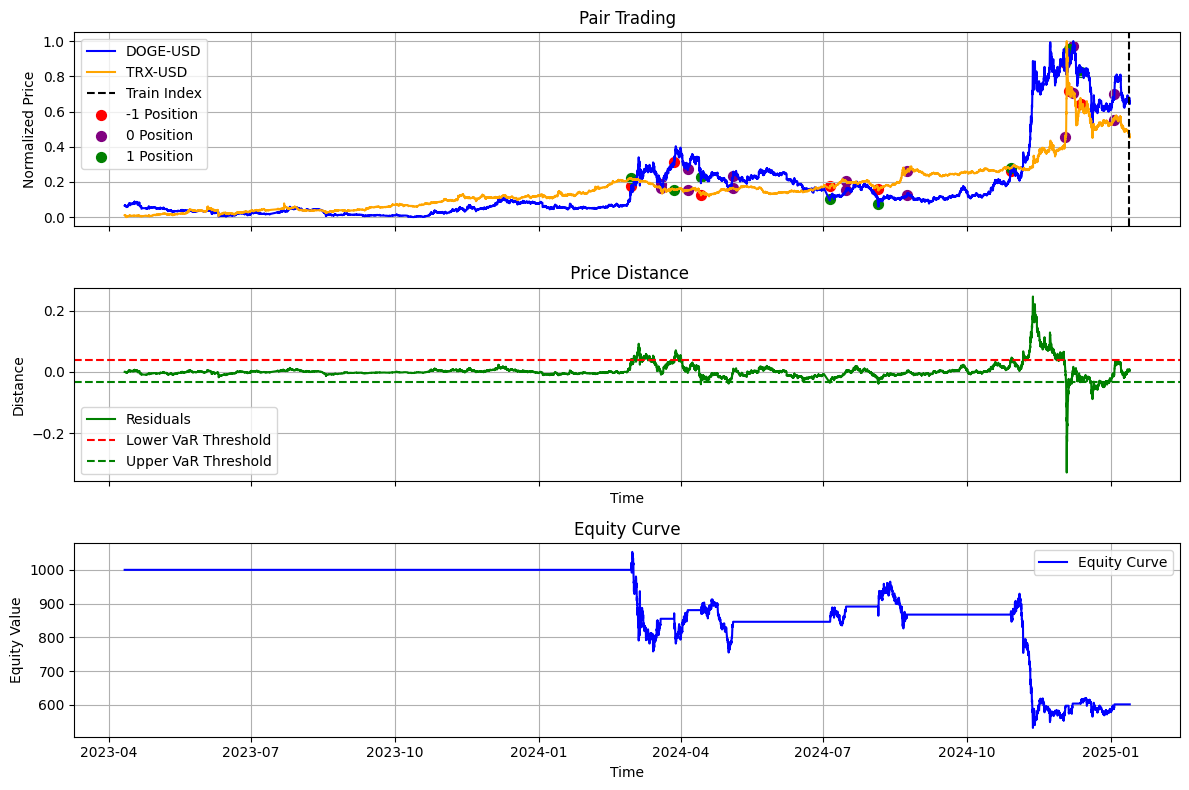

Initial Capital: 1000
Final Capital: 601.612475257639


In [20]:
# Initialize variables
initial_capital = 1000
volume_entry_perc = 0.1
comm = 0.002  # Commission per trade
margin = 5
max_trade = 1
bar_lookback = train_index + test_index

# Initialize variables
trade_counter = 0
capital = initial_capital
equity_curve = np.zeros(len(price))
balance = np.zeros(len(price))
unrlz_pnls = np.zeros(len(price))
positions = {pair[0]: 0, pair[1]: 0}
trade_log = []
trade_log_ = []
pricenormalize = (price - price.min()) / (price.max() - price.min())

# Backtest logic
for i in range(len(trades_signal)):
    action = trades_signal[i]
    # Daily update of equity curve based on current positions
    if positions[pair[0]] != 0 or positions[pair[1]] != 0:
        # Calculate daily PnL based on current prices
        unrlz_pnl = (
            (price[pair[0]].iloc[i] / price[pair[0]].iloc[i - 1] - 1) * positions[pair[0]] * capital * volume_entry_perc * margin +
            (price[pair[1]].iloc[i] / price[pair[1]].iloc[i - 1] - 1) * positions[pair[1]] * capital * volume_entry_perc * margin
        )
        unrlz_pnls[i] = unrlz_pnl
        capital += unrlz_pnl*(1-comm)
    equity_curve[i] = capital

    # Execute trades based on action
    if trade_counter < max_trade:
            if action == 1:
                positions[pair[0]] = -1
                positions[pair[1]] = 1
                trade_log.append((price.index[i], positions[pair[0]], pair[0], price[pair[0]].iloc[i]))
                trade_log.append((price.index[i], positions[pair[1]], pair[1], price[pair[1]].iloc[i]))
                trade_log_.append((price.index[i], positions[pair[0]], pricenormalize.columns[0], pricenormalize[pair[0]].iloc[i]))
                trade_log_.append((price.index[i], positions[pair[1]], pricenormalize.columns[1], pricenormalize[pair[1]].iloc[i]))
                trade_counter += 1


            elif action == 2:
                positions[pair[0]] = 1
                positions[pair[1]] = -1
                trade_log.append((price.index[i], positions[pair[0]], pair[0], price[pair[0]].iloc[i]))
                trade_log.append((price.index[i], positions[pair[1]], pair[1], price[pair[1]].iloc[i]))
                trade_log_.append((price.index[i], positions[pair[0]], pricenormalize.columns[0], pricenormalize[pair[0]].iloc[i]))
                trade_log_.append((price.index[i], positions[pair[1]], pricenormalize.columns[1], pricenormalize[pair[1]].iloc[i]))
                trade_counter += 1

    # Define the threshold for closing positions
    threshold = 0

    if trade_counter > 0 and close_signal[i]==1:
        # Close positions
        positions[pair[0]] = 0
        positions[pair[1]] = 0
        trade_log.append((price.index[i], positions[pair[0]], pair[0], price[pair[0]].iloc[i]))
        trade_log.append((price.index[i], positions[pair[1]], pair[1], price[pair[1]].iloc[i]))
        trade_log_.append((price.index[i], positions[pair[0]], pricenormalize.columns[0], pricenormalize[pair[0]].iloc[i]))
        trade_log_.append((price.index[i], positions[pair[1]], pricenormalize.columns[1], pricenormalize[pair[1]].iloc[i]))
        trade_counter = 0


# Final portfolio value calculation
final_value = capital + (
    (price[pair[0]].iloc[-1] if positions[pair[0]] == 1 else 0) +
    (price[pair[1]].iloc[-1] if positions[pair[1]] == -1 else 0)
)

# Create results DataFrame
results = pd.DataFrame({
    'PnL': unrlz_pnls,
    'Equity Curve': equity_curve
}, index=price.index)

# Create a DataFrame for trade markers
trade_markers = pd.DataFrame(columns=['Date', 'Price', 'Type'])

# Fill the DataFrame with trade data using a list to accumulate rows
trade_rows = []

for trade in trade_log_:
    trade_rows.append({
        'Date': trade[0],
        'Price': trade[3],
        'Type': trade[1]
    })

# Convert the list of rows into a DataFrame
trade_markers = pd.DataFrame(trade_rows)

if trade_markers.empty:
    trade_markers = pd.DataFrame(columns=['Date', 'Price', 'Type'])

# Create subplots
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Price Data with Entry and Close Points
axs[0].plot(pricenormalize[-bar_lookback:].index, pricenormalize[-bar_lookback:][pair[0]], label=pair[0], color='blue')
axs[0].plot(pricenormalize[-bar_lookback:].index, pricenormalize[-bar_lookback:][pair[1]], label=pair[1], color='orange')

# Add vertical line at train_index
axs[0].axvline(x=pricenormalize.index[train_index], color='black', linestyle='--', label='Train Index')

# Map trade types to colors and markers
trade_colors = {1: 'green', -1: 'red', 0: 'purple'}
trade_markers['Marker'] = trade_markers['Type'].map(trade_colors)

# Adding scatter points for trades
for trade_type, group in trade_markers.groupby('Type'):
    axs[0].scatter(group['Date'], group['Price'], color=trade_colors[trade_type],
                   marker='o', label=f'{trade_type} Position', s=50)
# Adding titles and labels for the first subplot
axs[0].set_title('Pair Trading')
axs[0].set_ylabel('Normalized Price')
axs[0].legend()
axs[0].grid()

# Second subplot: Residuals with VaR thresholds
axs[1].plot(distance_full[-bar_lookback:].index, distance_full[-bar_lookback:], label='Residuals', color='green')
axs[1].axhline(upper, color='red', linestyle='--', label='Lower VaR Threshold')
axs[1].axhline(lower, color='green', linestyle='--', label='Upper VaR Threshold')

# Adding titles and labels for the second subplot
axs[1].set_title(' Price Distance')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Distance')
axs[1].legend()
axs[1].grid()

axs[2].plot(distance_full[-bar_lookback:].index, results['Equity Curve'][-bar_lookback:], label='Equity Curve', color='blue')

# Adding titles and labels for the second subplot
axs[2].set_title('Equity Curve')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Equity Value')
axs[2].legend()
axs[2].grid()

plt.tight_layout()
plt.show()


# Output final results
print(f'Initial Capital: {initial_capital}')
print(f'Final Capital: {capital}')


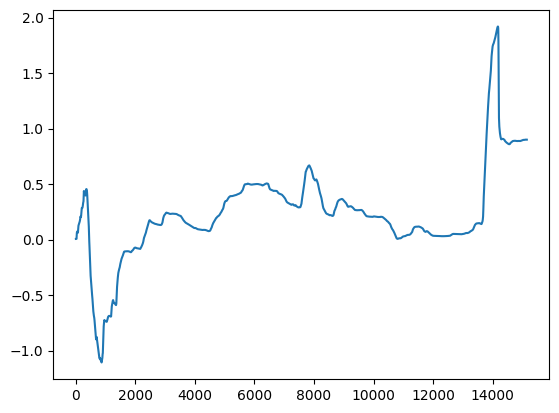

In [21]:
plt.plot(beta_estimates)